# Controlled pinned XLM-R token pooling
P0 includes attended special tokens; P1 excludes every tokenizer-designated special token. Both use the same final hidden states,128-token padding/truncation,prepared train/validation rows and arithmetic tweet-to-user means. No test access, encoder fine-tuning or other model component changes.
Pinned revision:e73636d4f797dec63c3081bb6ed5c7b0bb3f2089. Extraction is CPU float32, one thread, batch16, eval/no-grad. Record special-ID masks, hidden-state audit samples, hashes, runtime and memory. All P1 rows must retain at least one content token, otherwise stop. Legacy vectors remain immutable.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/token_pooling_v1.json').exists())
sys.path.insert(0, str(ROOT))
from src.xlmr_pooling import extract, verify as verify_embeddings
embedding_dir = ROOT / 'final_data/embedding_versions/token_pooling_v1/20260923T103253436409Z_f2cfb2f4'
print('EMBEDDING_VERSION:', embedding_dir)
print(verify_embeddings(ROOT, embedding_dir))

EMBEDDING_VERSION: C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation\final_data\embedding_versions\token_pooling_v1\20260923T103253436409Z_f2cfb2f4


{'train_tweets': 12976, 'validation_tweets': 2618, 'all_token_masks_retokenized': True, 'saved_hidden_pooling_audited': True, 'test_access': False, 'P0_legacy_agreement': {'train_tweet': {'classification': 'near-exact', 'exact': False, 'within_declared_tolerance': True, 'atol': 1e-05, 'rtol': 1e-05, 'min_cosine': 0.9999999999981023, 'max_coordinate_difference': 1.9550323486328125e-05}, 'train_user': {'classification': 'near-exact', 'exact': False, 'within_declared_tolerance': True, 'atol': 1e-05, 'rtol': 1e-05, 'min_cosine': 0.9999999999999688, 'max_coordinate_difference': 3.814697265625e-06}, 'validation_tweet': {'classification': 'near-exact', 'exact': False, 'within_declared_tolerance': True, 'atol': 1e-05, 'rtol': 1e-05, 'min_cosine': 0.999999999999953, 'max_coordinate_difference': 3.814697265625e-06}, 'validation_user': {'classification': 'near-exact', 'exact': False, 'within_declared_tolerance': True, 'atol': 1e-05, 'rtol': 1e-05, 'min_cosine': 0.999999999999991, 'max_coordinate_

## Paired classifiers
Use the unchanged16,897-parameter temporal-plus-text model. Seeds42/43/44,671train/144validation users,50epochs,batch32,AdamW lr.001/decay.0001,dropout.3,positive weight540/131. Paired initialization and actual batch orders must match. Select earliest minimum unweighted validation BCE; retain final checkpoints; threshold.5.
Mean user aggregation and missing-text masking are identical. The temporal-only model is context, not a capacity-matched control. Consistent development improvement requires higher paired F1 in every seed and no lower mean AP. No automatic promotion.

In [2]:
from src.token_pooling import run, verify
output_dir = run(ROOT, embedding_dir)
print('OUTPUT_VERSION:', output_dir)
print(verify(ROOT, output_dir))

Training P0, seed 42


P0, seed 42, epoch 25: validation BCE 0.6342


P0, seed 42, epoch 50: validation BCE 0.6910


Training P1, seed 42


P1, seed 42, epoch 25: validation BCE 0.6354


...

Training P1, seed 44


P1, seed 44, epoch 25: validation BCE 0.5487


P1, seed 44, epoch 50: validation BCE 0.5344


OUTPUT_VERSION: C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation\results\versions\token_pooling_v1\20260927T131239185953Z_31718179


{'training_runs': 6, 'checkpoints_reloaded': 12, 'keyed_representation_matrices': 4, 'single_tweet_users_counted': {'train': 152, 'validation': 28}, 'test_inputs_parsed': 0}


,arm,policy,cohort,bot_f1_mean,bot_f1_std,bot_precision_mean,bot_precision_std,bot_recall_mean,bot_recall_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,brier_mean,brier_std
0,P0,best_unweighted_validation_loss,11_to_50,0.469403,0.009668,0.365003,0.029356,0.666667,0.066667,0.687440,0.016482,0.543416,0.019422,0.242762,0.014748
1,P0,best_unweighted_validation_loss,2_to_10,0.569052,0.035981,0.558275,0.070308,0.583333,0.000000,0.796512,0.013427,0.650423,0.048237,0.146820,0.012516
2,P0,best_unweighted_validation_loss,all,0.478829,0.025865,0.387486,0.039562,0.630952,0.020620,0.758210,0.007995,0.544713,0.008544,0.181758,0.015302
3,P0,best_unweighted_validation_loss,missing_text,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,P0,best_unweighted_validation_loss,one_tweet,0.207407,0.200411,0.125000,0.125000,0.666667,0.577350,0.876543,0.119057,0.319444,0.187885,0.117483,0.024336
5,P0,last,11_to_50,0.447347,0.079781,0.358586,0.079734,0.600000,0.066667,0.666667,0.028949,0.543528,0.026125,0.250860,0.032122
6,P0,last,2_to_10,0.558263,0.066607,0.543821,0.117397,0.583333,0.000000,0.768734,0.021435,0.595502,0.050485,0.156173,0.030271
7,P0,last,all,0.468010,0.076272,0.384755,0.089393,0.607143,0.035714,0.733580,0.025288,0.520573,0.024708,0.189741,0.033425
8,P0,last,missing_text,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,P0,last,one_tweet,0.307407,0.167160,0.189815,0.124485,1.000000,0.000000,0.839506,0.140220,0.422619,0.500106,0.122525,0.050809


,seed,policy,cohort,delta_bot_f1,delta_bot_precision,delta_bot_recall,delta_roc_auc,delta_average_precision,delta_brier
0,42,best_unweighted_validation_loss,all,0.011538,0.013846,0.000000,-0.001847,-0.003370,-0.000029
1,42,best_unweighted_validation_loss,one_tweet,0.000000,0.000000,0.000000,0.000000,0.000000,-0.000443
2,42,best_unweighted_validation_loss,2_to_10,0.044872,0.083333,0.000000,0.003876,0.001871,-0.000400
3,42,best_unweighted_validation_loss,11_to_50,0.000000,0.000000,0.000000,-0.005797,-0.002955,0.000495
4,42,best_unweighted_validation_loss,missing_text,NaN,NaN,NaN,NaN,NaN,NaN
5,42,last,all,-0.013136,-0.014528,0.000000,0.001232,0.005475,0.007698
6,42,last,one_tweet,0.000000,0.000000,0.000000,0.037037,0.023810,0.007632
7,42,last,2_to_10,-0.031146,-0.043344,0.000000,-0.007752,0.034946,0.006540
8,42,last,11_to_50,-0.007729,-0.008602,0.000000,0.004348,-0.003047,0.008772
9,42,last,missing_text,NaN,NaN,NaN,NaN,NaN,NaN


,seed,arm,policy,epoch,n,bots,threshold,bot_precision,bot_recall,bot_f1,...,fp,fn,tp,predicted_bots,roc_auc,average_precision,pos_weight,parameter_count,validation_weighted_loss,validation_unweighted_loss
0,42,temporal_branch,best_unweighted_validation_loss,12,144,28,0.5,0.367347,0.642857,0.467532,...,31,10,18,49,0.773399,0.534680,4.122137,4081,0.934310,0.557748
1,42,temporal_branch,last,50,144,28,0.5,0.333333,0.678571,0.447059,...,38,9,19,57,0.714901,0.475800,4.122137,4081,1.319343,0.721112
2,43,temporal_branch,best_unweighted_validation_loss,21,144,28,0.5,0.365385,0.678571,0.475000,...,33,9,19,52,0.758621,0.557178,4.122137,4081,1.000583,0.538830
3,43,temporal_branch,last,50,144,28,0.5,0.320755,0.607143,0.419753,...,36,11,17,53,0.732451,0.527168,4.122137,4081,1.245663,0.616335
4,44,temporal_branch,best_unweighted_validation_loss,16,144,28,0.5,0.400000,0.642857,0.493151,...,27,10,18,45,0.771552,0.566855,4.122137,4081,0.937399,0.532124
5,44,temporal_branch,last,50,144,28,0.5,0.352941,0.642857,0.455696,...,33,10,18,51,0.740764,0.552051,4.122137,4081,1.191297,0.606488


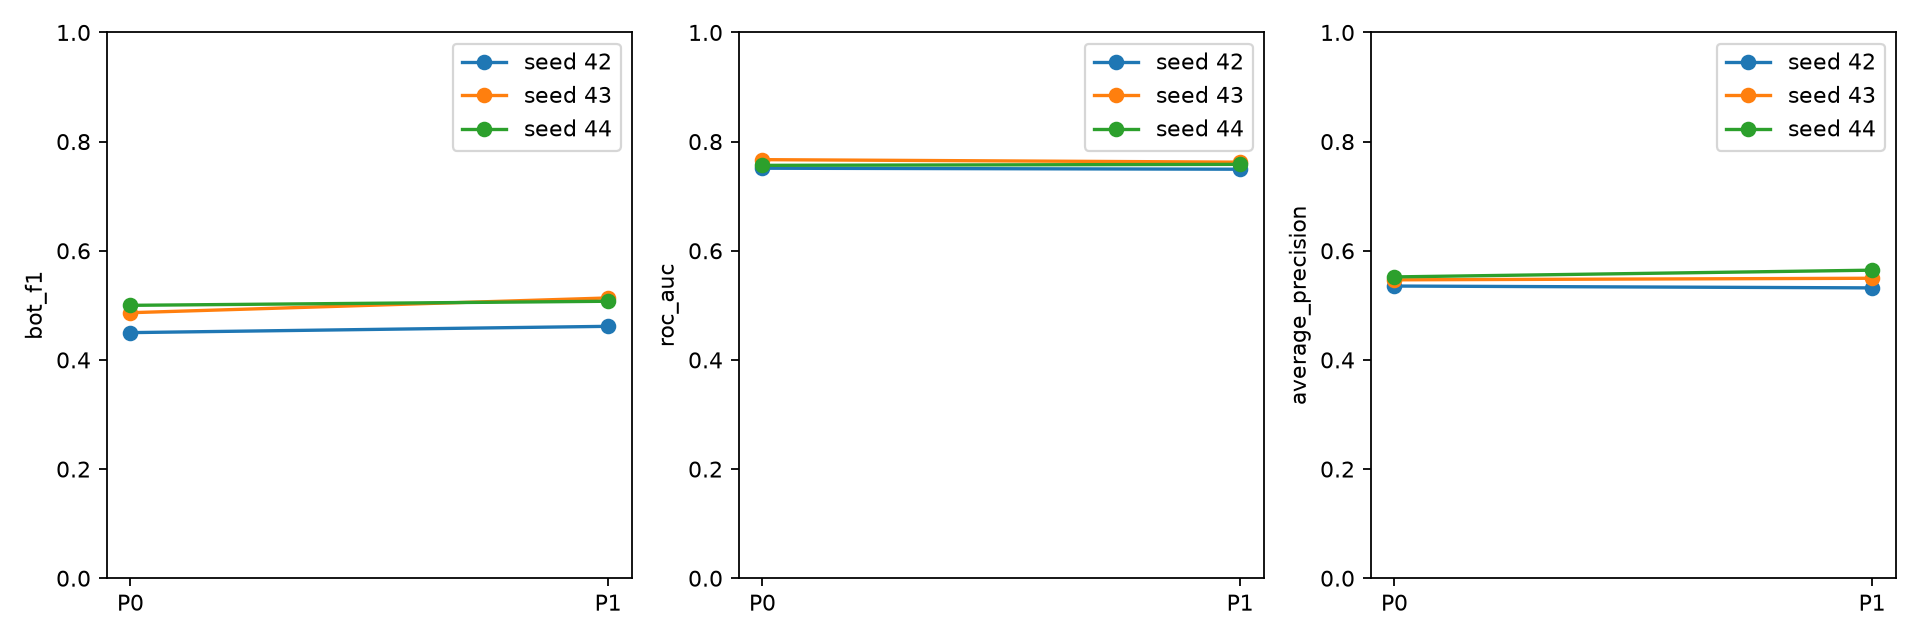

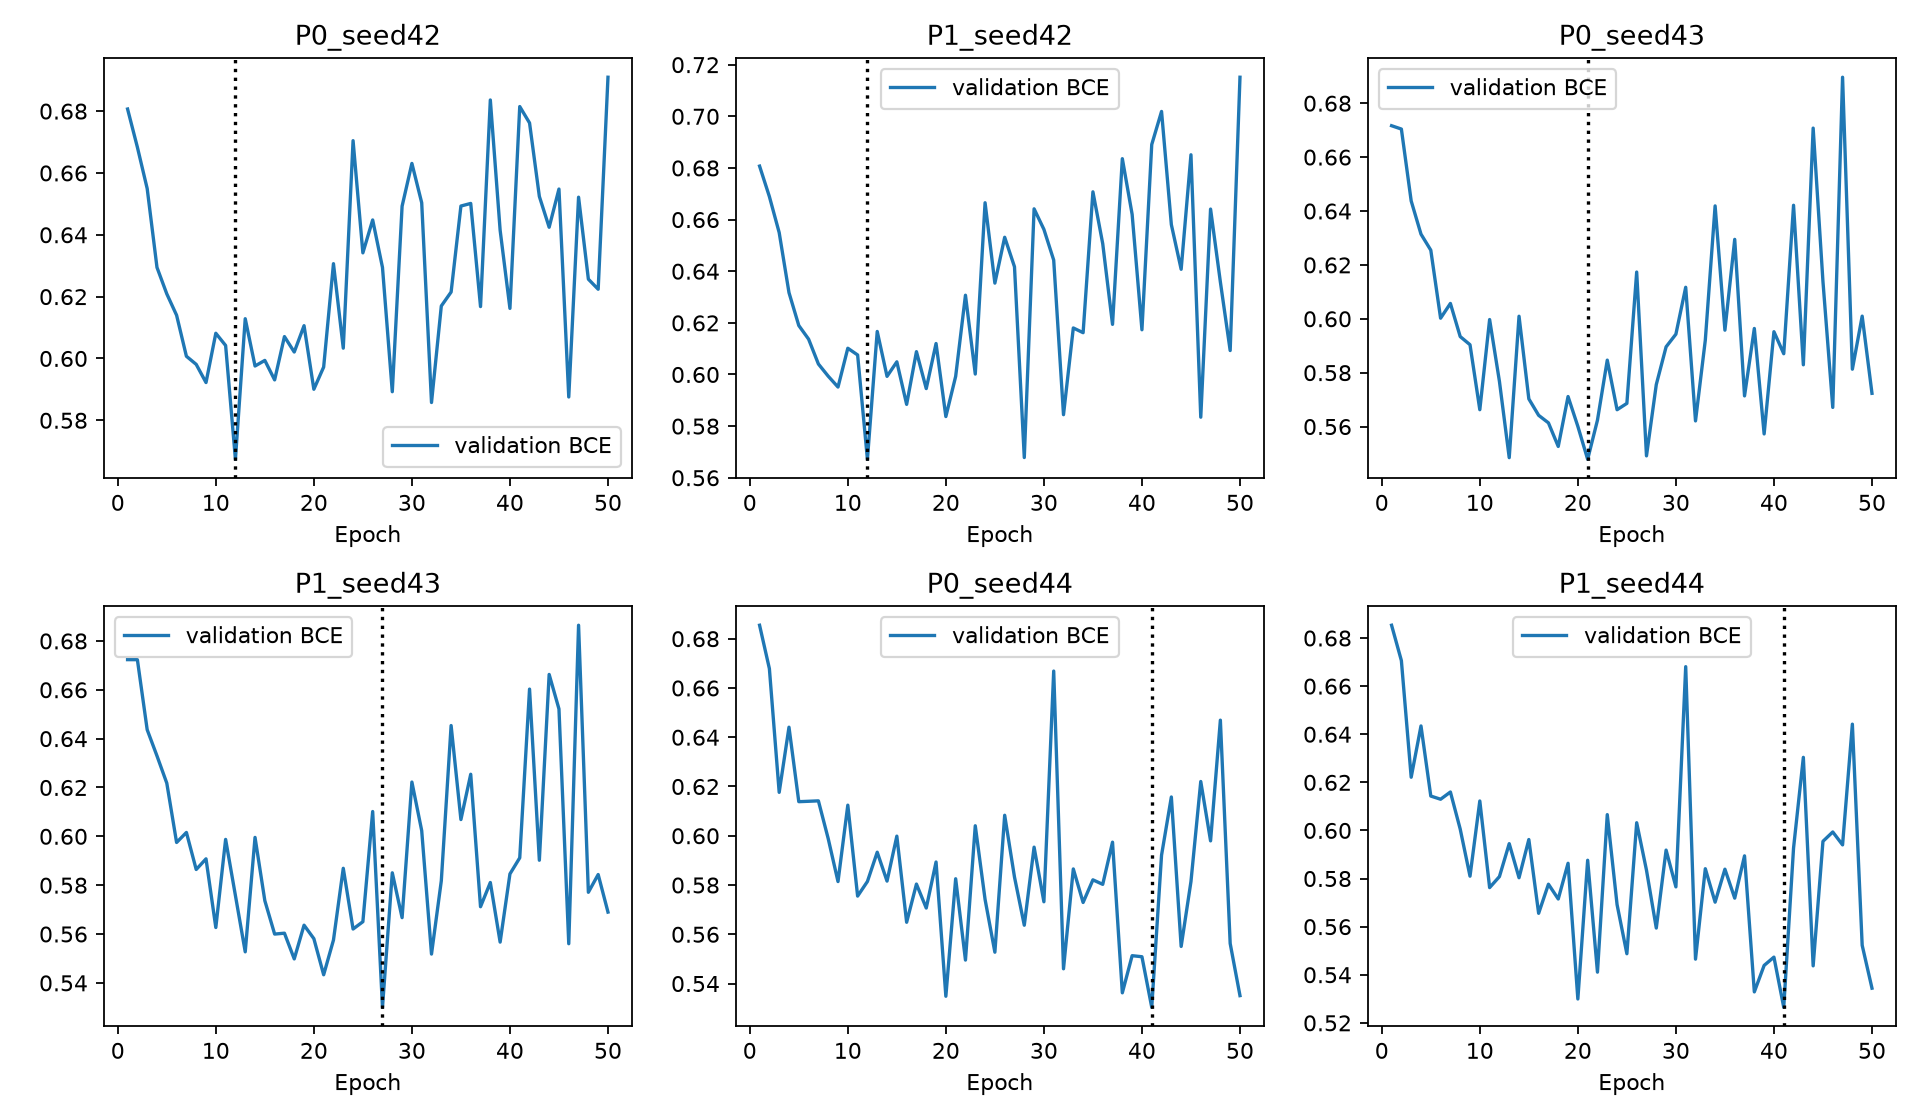

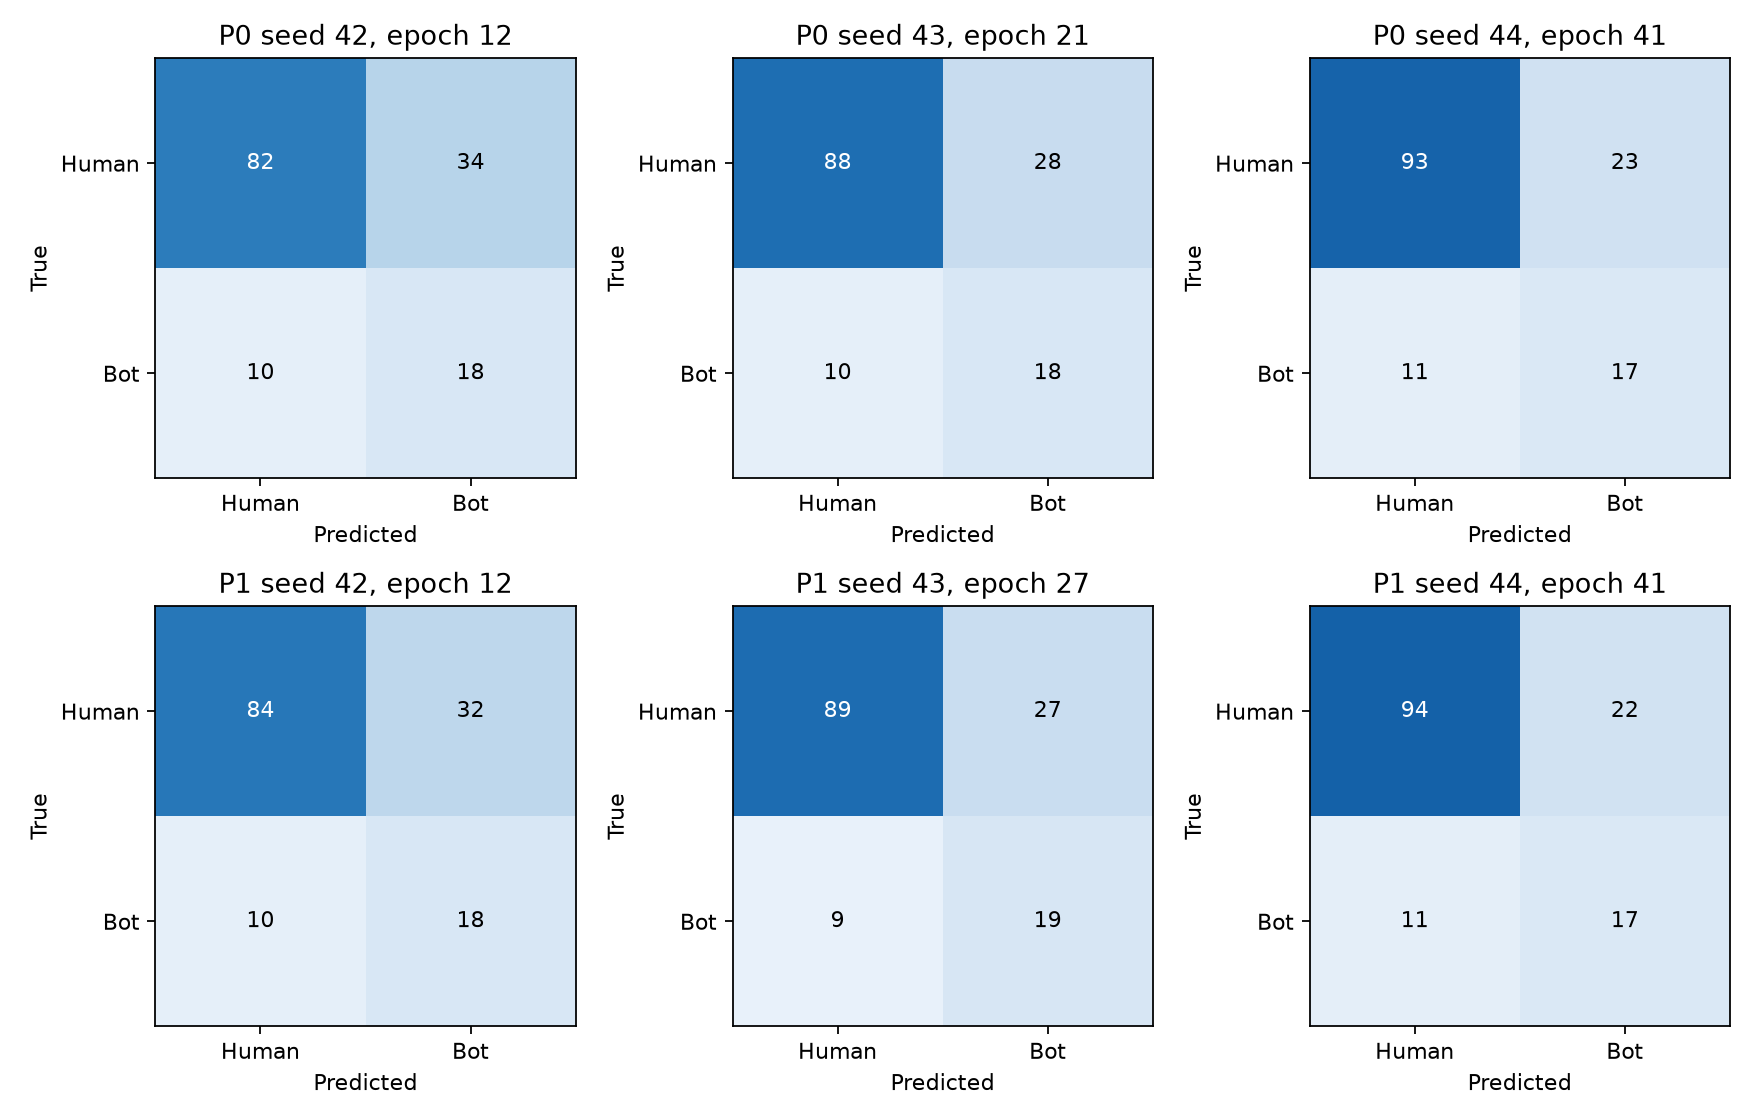

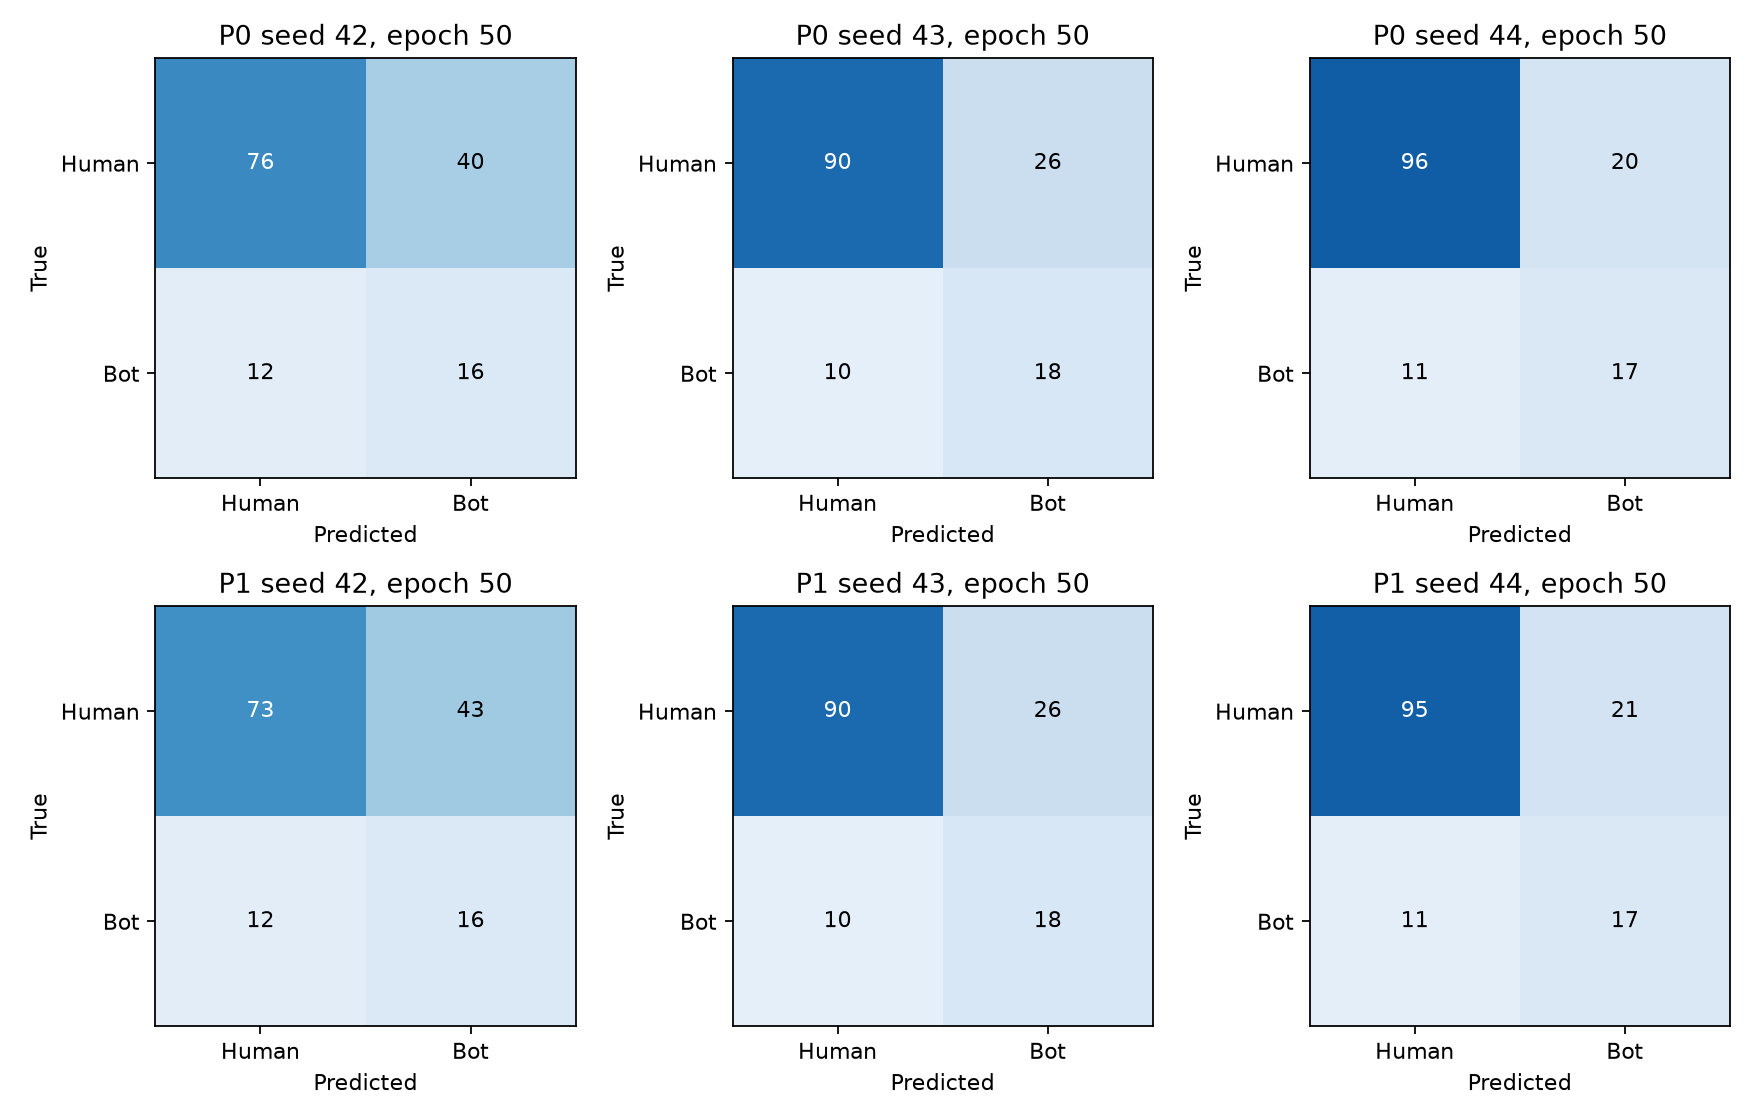

In [3]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv(output_dir / 'seed_summary.csv'))
display(pd.read_csv(output_dir / 'paired_effects.csv'))
display(pd.read_csv(output_dir / 'temporal_reference_validation.csv'))
display(Image(filename=str(output_dir / 'figures/paired_metrics.png')))
display(Image(filename=str(output_dir / 'figures/learning_curves.png')))
display(Image(filename=str(output_dir / 'figures/confusion_selected.png')))
display(Image(filename=str(output_dir / 'figures/confusion_final.png')))

In [4]:
display(pd.read_csv(embedding_dir / 'representation_difference_summary.csv'))
display(pd.read_csv(embedding_dir / 'special_token_counts.csv'))
norms = pd.read_csv(embedding_dir / 'embedding_norms.csv')
display(norms.groupby(['split','arm','level']).l2_norm.describe())
print((embedding_dir / 'agreement.json').read_text())
print((embedding_dir / 'runtime.json').read_text())

,split,level,comparison,metric,count,mean,std,min,5%,50%,95%,99%,max
0,train,tweet,P0_vs_legacy,cosine_similarity,12976.0,1.000000e+00,1.695042e-14,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
1,train,tweet,P0_vs_legacy,l2_distance,12976.0,1.527152e-06,7.896890e-07,5.510668e-07,7.696653e-07,1.299105e-06,2.645510e-06,4.060266e-06,3.668186e-05
2,train,tweet,P0_vs_legacy,max_absolute_difference,12976.0,8.517919e-07,8.106953e-07,8.195639e-08,1.266599e-07,4.768372e-07,1.907349e-06,3.814697e-06,1.955032e-05
3,train,tweet,P0_vs_legacy,mean_signed_difference,12976.0,2.154465e-11,1.696891e-09,-8.724726e-09,-2.825296e-09,5.730675e-12,2.829754e-09,4.480505e-09,2.148954e-08
4,train,tweet,P0_vs_legacy,fresh_l2_norm,12976.0,1.892565e+01,8.118820e-02,1.833478e+01,1.878213e+01,1.893960e+01,1.902976e+01,1.905255e+01,1.912756e+01
5,train,tweet,P0_vs_legacy,legacy_l2_norm,12976.0,1.892565e+01,8.118822e-02,1.833478e+01,1.878213e+01,1.893960e+01,1.902976e+01,1.905255e+01,1.912756e+01
6,train,tweet,P0_vs_legacy,relative_l2_distance,12976.0,8.076103e-08,4.194044e-08,2.895068e-08,4.051024e-08,6.869773e-08,1.403983e-07,2.150146e-07,1.950868e-06
7,train,tweet,P1_vs_P0,cosine_similarity,12976.0,9.995712e-01,1.537982e-03,9.562295e-01,9.986721e-01,9.998062e-01,9.999597e-01,9.999752e-01,9.999824e-01
8,train,tweet,P1_vs_P0,l2_distance,12976.0,4.633991e-01,3.276881e-01,1.156075e-01,1.763912e-01,3.851918e-01,9.967468e-01,1.439637e+00,5.624778e+00
9,train,tweet,P1_vs_P0,max_absolute_difference,12976.0,4.363490e-01,3.057021e-01,1.042051e-01,1.669743e-01,3.634763e-01,9.325359e-01,1.338722e+00,5.177831e+00


,split,special_id,token,attended_occurrences,retained_P1
0,train,0,<s>,12976,0
1,train,2,</s>,12976,0
2,train,3,<unk>,991,0
3,train,1,<pad>,0,0
4,train,250001,<mask>,0,0
5,validation,0,<s>,2618,0
6,validation,2,</s>,2618,0
7,validation,3,<unk>,206,0
8,validation,1,<pad>,0,0
9,validation,250001,<mask>,0,0


count       mean       std        min        25%  \
split      arm level                                                       
train      P0  tweet  12976.0  18.925646  0.081188  18.334776  18.872394   
               user     671.0  18.907315  0.076823  18.464261  18.866186   
           P1  tweet  12976.0  19.033196  0.041461  18.699206  19.005237   
               user     671.0  19.023456  0.040525  18.831814  18.997801   
validation P0  tweet   2618.0  18.923926  0.075286  18.402125  18.871950   
               user     144.0  18.904999  0.062583  18.705213  18.878375   
           P1  tweet   2618.0  19.032137  0.041477  18.686109  19.004590   
               user     144.0  19.019358  0.032836  18.944397  18.998023   

                            50%        75%        max  
split      arm level                                   
train      P0  tweet  18.939601  18.988790  19.127559  
               user   18.910120  18.955055  19.086084  
           P1  tweet  19.034952  19.062072  19.233925  
               user   19.020633  19.045392  19.220062  
validation P0  tweet  18.935023  18.982050  19.084180  
               user   18.906076  18.940535  19.035177  
           P1  tweet  19.034018  19.060440  19.163158  
               user   19.017191  19.037881  19.102550

{
  "train_tweet": {
    "classification": "near-exact",
    "exact": false,
    "within_declared_tolerance": true,
    "atol": 1e-05,
    "rtol": 1e-05,
    "min_cosine": 0.9999999999981023,
    "max_coordinate_difference": 1.9550323486328125e-05
  },
  "train_user": {
    "classification": "near-exact",
    "exact": false,
    "within_declared_tolerance": true,
    "atol": 1e-05,
    "rtol": 1e-05,
    "min_cosine": 0.9999999999999688,
    "max_coordinate_difference": 3.814697265625e-06
  },
  "validation_tweet": {
    "classification": "near-exact",
    "exact": false,
    "within_declared_tolerance": true,
    "atol": 1e-05,
    "rtol": 1e-05,
    "min_cosine": 0.999999999999953,
    "max_coordinate_difference": 3.814697265625e-06
  },
  "validation_user": {
    "classification": "near-exact",
    "exact": false,
    "within_declared_tolerance": true,
    "atol": 1e-05,
    "rtol": 1e-05,
    "min_cosine": 0.999999999999991,
    "max_coordinate_difference": 3.814697265625e-06
  }
}